# Anomaly detection: learn only what *real* images look like

The trained probes learn "real vs. the 12 generators in training", so images from new
generators can fall on the "real" side. Here we instead model **only real images** and flag
anything that doesn't fit, without using any fake images at all, not even to pick the cutoff.

**Features** (same DINOv2 ViT-L/14 setup as RIGID; one noise draw, λ = 0.05):
`clean` = embedding of the image, `diff` = how the embedding moves under noise,
`clean+diff` = both.

**Scores** (higher = less real-like):
- **Mahalanobis**: distance from the centre of the real images, measured in units of how much
  real images vary in each direction. Covariance estimated with Ledoit-Wolf shrinkage; optionally
  after PCA to 256 dims (which discards the low-variance directions).
- **kNN**: mean cosine distance to the 10 nearest real training images.

**Cutoff**: the 95th percentile of scores on held-out *real* training images → ~5% of
in-distribution real images flagged, by construction.

**Compared with**: plain RIGID (cosine similarity, no training) and the two trained probes
(`model/DINOv2/Frozen DINO model/probes/probe_clean_diff*.joblib`, which *did* see fakes).

In [1]:
import random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader

from rigid import RIGIDDetector
from rigid_probe import build_features, make_mlp
from utils.datasets import IMAGE_EXTS, ImageListDataset, skip_none_collate

SEED = 0
TRAIN_EMB = Path("results/embeddings")       # embeddings the probes were trained on
EVAL_CACHE = Path("results/embeddings_eval")  # cache for the test-set embeddings below

## 1. Real training images (ImageNet + RAISE) → fit / held-out split

In [2]:
parts = [np.load(f) for f in sorted(TRAIN_EMB.glob("*.npz"))]
real = [p for p in parts if p["label"][0] == 1]
clean_real = np.concatenate([p["clean"] for p in real]).astype(np.float32)
noisy_real = np.concatenate([p["noisy"] for p in real]).astype(np.float32)
print("real training images:", {str(p['source'][0]): len(p['label']) for p in real})

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(clean_real))
n_fit = int(0.8 * len(perm))
fit_idx, hold_idx = perm[:n_fit], perm[n_fit:]
print(f"fit on {len(fit_idx)}, held out {len(hold_idx)} for the cutoff")

real training images: {'imagenet': 4915, 'raise': 999}
fit on 4731, held out 1183 for the cutoff


## 2. Test sets (none of these images were used in training)

Each test image is embedded once (clean + one noisy copy) and cached in `results/embeddings_eval/`.

In [3]:
D = Path("/Volumes/Kioxia SSD/datasets")
UNSPLASH = D / "kagglehub/datasets/rhythmghai/ai-vs-real-images-dataset/versions/1"
N_PER_FOLDER = 200
EVAL_SETS = {   # name: (real folders, {fake source: folder})
    "cutoff_set/test (LSUN, FFHQ, ImageNet-unseen | ADM, StyleGAN2, LDM, DiT, GigaGAN)": (
        [D / "cutoff_set/test/real"],
        {d.name: d for d in sorted((D / "cutoff_set/test/fake").iterdir()) if d.is_dir()}),
    "COCO | SD 3, SD 3.5, Midjourney 6": (
        [D / "coco_ai/real/coco"],
        {"sd3": D / "coco_ai/fake/sd3", "sd35": D / "coco_ai/fake/sd35", "midjourney6": D / "coco_ai/fake/midjourney6"}),
    "Unsplash | Stable Diffusion": (
        [UNSPLASH / "real_dataset"], {"unsplash_sd": UNSPLASH / "Ai_generated_dataset"}),
}

detector = RIGIDDetector(lamb=0.05, model_name="dinov2_vitl14", seed=100)

def list_images(folder, n):
    files = sorted(p for p in Path(folder).rglob("*")
                   if p.suffix.lower() in IMAGE_EXTS and ".ipynb_checkpoints" not in p.parts)
    return sorted(random.Random(SEED).sample(files, n)) if len(files) > n else files

@torch.no_grad()
def embed_folder(folder, n=N_PER_FOLDER):
    cache = EVAL_CACHE / (str(folder).replace("/", "_").strip("_") + f"_n{n}.npz")
    if cache.exists():
        d = np.load(cache)
        return d["clean"].astype(np.float32), d["noisy"].astype(np.float32)
    files = list_images(folder, n)
    loader = DataLoader(ImageListDataset([(p, 0, "") for p in files], detector.transform),
                        batch_size=32, num_workers=4, collate_fn=skip_none_collate)
    gen = torch.Generator().manual_seed(100)
    clean, noisy = [], []
    for batch in loader:
        if batch is None:
            continue
        x = batch[0].to(detector.device)
        noise = torch.randn(x.shape, generator=gen).to(detector.device)
        clean.append(detector.model(x).float().cpu())
        noisy.append(detector.model(x + noise * detector.lamb).float().cpu())
    clean, noisy = torch.cat(clean).numpy(), torch.cat(noisy).numpy()
    EVAL_CACHE.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(cache, clean=clean.astype(np.float16), noisy=noisy.astype(np.float16))
    print(f"  embedded {len(clean):>4} images from {folder}")
    return clean, noisy

evals = {}   # name -> dict(clean, noisy, label (1 = real), source)
for name, (real_dirs, fakes) in EVAL_SETS.items():
    C, N, L, S = [], [], [], []
    for d in real_dirs:
        c, n = embed_folder(d); C.append(c); N.append(n); L += [1] * len(c); S += ["real"] * len(c)
    for src, d in fakes.items():
        c, n = embed_folder(d); C.append(c); N.append(n); L += [0] * len(c); S += [src] * len(c)
    evals[name] = {"clean": np.concatenate(C), "noisy": np.concatenate(N), "label": np.array(L), "source": np.array(S)}
    print(f"{name}: {sum(L)} real, {len(L) - sum(L)} fake")

Using cache found in /Users/michael/.cache/torch/hub/facebookresearch_dinov2_main


  embedded   50 images from /Volumes/Kioxia SSD/datasets/cutoff_set/test/fake/imagenet_dit
  embedded   50 images from /Volumes/Kioxia SSD/datasets/cutoff_set/test/fake/imagenet_gigagan
  embedded   50 images from /Volumes/Kioxia SSD/datasets/cutoff_set/test/fake/lsun_adm
cutoff_set/test (LSUN, FFHQ, ImageNet-unseen | ADM, StyleGAN2, LDM, DiT, GigaGAN): 150 real, 250 fake
  embedded  200 images from /Volumes/Kioxia SSD/datasets/coco_ai/real/coco
  embedded  200 images from /Volumes/Kioxia SSD/datasets/coco_ai/fake/sd3
  embedded  200 images from /Volumes/Kioxia SSD/datasets/coco_ai/fake/sd35
  embedded  200 images from /Volumes/Kioxia SSD/datasets/coco_ai/fake/midjourney6
COCO | SD 3, SD 3.5, Midjourney 6: 200 real, 600 fake
  embedded  200 images from /Volumes/Kioxia SSD/datasets/kagglehub/datasets/rhythmghai/ai-vs-real-images-dataset/versions/1/real_dataset
  embedded  200 images from /Volumes/Kioxia SSD/datasets/kagglehub/datasets/rhythmghai/ai-vs-real-images-dataset/versions/1/Ai_g

## 3. Detectors

Every detector returns a score where **higher = more likely AI-generated**.

In [4]:
def fit_mahalanobis(kind, pca_dims=None):
    X = build_features(clean_real[fit_idx], noisy_real[fit_idx], kind)
    scaler = StandardScaler().fit(X)
    Z = scaler.transform(X)
    pca = PCA(pca_dims, random_state=SEED).fit(Z) if pca_dims else None
    lw = LedoitWolf().fit(pca.transform(Z) if pca else Z)
    def score(clean, noisy):
        Z = scaler.transform(build_features(clean, noisy, kind))
        return lw.mahalanobis(pca.transform(Z) if pca else Z)
    return score

def fit_knn(kind, k=10):
    X = build_features(clean_real[fit_idx], noisy_real[fit_idx], kind)
    scaler = StandardScaler().fit(X)
    nn = NearestNeighbors(n_neighbors=k, metric="cosine").fit(scaler.transform(X))
    return lambda clean, noisy: nn.kneighbors(scaler.transform(build_features(clean, noisy, kind)))[0].mean(1)

def load_probe(path):
    b = joblib.load(path)
    if b["meta"].get("model") == "mlp":
        net = make_mlp(b["meta"]["in_dim"], b["meta"]["hidden"]); net.load_state_dict(b["state_dict"]); net.eval()
        def p_real(X):
            with torch.no_grad():
                return torch.sigmoid(net(torch.tensor(X, dtype=torch.float32))).squeeze(1).numpy()
    else:
        p_real = lambda X: b["clf"].predict_proba(X)[:, list(b["clf"].classes_).index(1)]
    return lambda clean, noisy: 1 - p_real(b["scaler"].transform(build_features(clean, noisy, b["meta"]["features"])))

def rigid_score(clean, noisy):           # 1 - cosine: higher = less stable = more "fake"
    return 1 - build_features(clean, noisy, "cos")[:, 0]

detectors = {
    "RIGID (no training)":            ("—", rigid_score),
    "Mahalanobis diff":               ("real only", fit_mahalanobis("diff")),
    "Mahalanobis diff, PCA-256":      ("real only", fit_mahalanobis("diff", 256)),
    "Mahalanobis clean":              ("real only", fit_mahalanobis("clean")),
    "Mahalanobis clean, PCA-256":     ("real only", fit_mahalanobis("clean", 256)),
    "Mahalanobis clean+diff":         ("real only", fit_mahalanobis("clean+diff")),
    "Mahalanobis clean+diff, PCA-256":("real only", fit_mahalanobis("clean+diff", 256)),
    "kNN diff (k=10)":                ("real only", fit_knn("diff")),
    "Probe: logistic regression":     ("real + fake", load_probe("model/DINOv2/Frozen DINO model/probes/probe_clean_diff.joblib")),
    "Probe: MLP":                     ("real + fake", load_probe("model/DINOv2/Frozen DINO model/probes/probe_clean_diff_mlp.joblib")),
}
print(f"{len(detectors)} detectors ready")

10 detectors ready


## 4. AUROC on each test set (threshold-free)

0.5 = chance. Per-generator columns compare that generator's images with all real images in its set.

In [5]:
rows = []
for det, (trained_on, score) in detectors.items():
    row = {"detector": det, "trained on": trained_on}
    for name, e in evals.items():
        s = score(e["clean"], e["noisy"])
        fake = 1 - e["label"]
        row[name.split(" |")[0]] = roc_auc_score(fake, s)
        for src in np.unique(e["source"][fake == 1]):
            m = (e["label"] == 1) | (e["source"] == src)
            row[f"  {src}"] = roc_auc_score(fake[m], s[m])
    rows.append(row)
auc = pd.DataFrame(rows).set_index(["detector", "trained on"])
overall = [c for c in auc.columns if not c.startswith("  ")]
print("Overall AUROC per test set:")
display(auc[overall].round(3))
print("Per generator:")
display(auc[[c for c in auc.columns if c.startswith("  ")]].round(3))

Overall AUROC per test set:


,,"cutoff_set/test (LSUN, FFHQ, ImageNet-unseen",COCO,Unsplash
detector,trained on,,,
RIGID (no training),—,0.769,0.537,0.867
Mahalanobis diff,real only,0.767,0.556,0.868
"Mahalanobis diff, PCA-256",real only,0.768,0.543,0.872
Mahalanobis clean,real only,0.414,0.533,0.437
"Mahalanobis clean, PCA-256",real only,0.497,0.511,0.557
Mahalanobis clean+diff,real only,0.763,0.558,0.863
"Mahalanobis clean+diff, PCA-256",real only,0.774,0.544,0.878
kNN diff (k=10),real only,0.480,0.635,0.320
Probe: logistic regression,real + fake,0.890,0.800,0.804


Per generator:


,,ffhq_ldm,ffhq_stylegan2,imagenet_dit,imagenet_gigagan,lsun_adm,midjourney6,sd3,sd35,unsplash_sd
detector,trained on,,,,,,,,,
RIGID (no training),—,0.957,0.990,0.520,0.809,0.568,0.593,0.530,0.487,0.867
Mahalanobis diff,real only,0.956,0.988,0.524,0.805,0.564,0.620,0.545,0.502,0.868
"Mahalanobis diff, PCA-256",real only,0.950,0.989,0.528,0.810,0.561,0.603,0.533,0.494,0.872
Mahalanobis clean,real only,0.489,0.411,0.277,0.290,0.601,0.518,0.558,0.524,0.437
"Mahalanobis clean, PCA-256",real only,0.361,0.279,0.736,0.647,0.463,0.523,0.488,0.522,0.557
Mahalanobis clean+diff,real only,0.955,0.989,0.498,0.796,0.575,0.624,0.549,0.500,0.863
"Mahalanobis clean+diff, PCA-256",real only,0.943,0.988,0.600,0.820,0.520,0.588,0.534,0.510,0.878
kNN diff (k=10),real only,0.512,0.324,0.499,0.529,0.535,0.710,0.584,0.610,0.320
Probe: logistic regression,real + fake,0.886,0.985,0.901,0.967,0.712,0.802,0.766,0.831,0.804


## 5. Using a cutoff chosen from real images only

For the anomaly detectors, the cutoff is the 95th percentile of held-out *real training* images
(so ~5% of ImageNet/RAISE-like real images are flagged). The probes use P(AI) ≥ 0.5.
How does that hold up on new real sources and unseen generators?

In [6]:
cut_rows = []
for det, (trained_on, score) in detectors.items():
    if det.startswith("RIGID"):
        continue
    if trained_on == "real only":
        cutoff = np.percentile(score(clean_real[hold_idx], noisy_real[hold_idx]), 95)
        rule = "95th pct of held-out real"
    else:
        cutoff, rule = 0.5, "P(AI) ≥ 0.5"
    row = {"detector": det, "cutoff rule": rule}
    for name, e in evals.items():
        flag = score(e["clean"], e["noisy"]) >= cutoff
        short = name.split(" |")[0]
        row[(short, "real flagged")] = flag[e["label"] == 1].mean()
        row[(short, "fakes caught")] = flag[e["label"] == 0].mean()
    cut_rows.append(row)
cut = pd.DataFrame(cut_rows).set_index(["detector", "cutoff rule"])
cut.columns = pd.MultiIndex.from_tuples(cut.columns)
display(cut.round(2))

cutoff_set/test (LSUN, FFHQ, ImageNet-unseen  \
                                                                                          real flagged   
detector                        cutoff rule                                                              
Mahalanobis diff                95th pct of held-out real                                         0.16   
Mahalanobis diff, PCA-256       95th pct of held-out real                                         0.17   
Mahalanobis clean               95th pct of held-out real                                         0.18   
Mahalanobis clean, PCA-256      95th pct of held-out real                                         0.01   
Mahalanobis clean+diff          95th pct of held-out real                                         0.17   
Mahalanobis clean+diff, PCA-256 95th pct of held-out real                                         0.12   
kNN diff (k=10)                 95th pct of held-out real                                         0.08   
Probe: logistic regression      P(AI) ≥ 0.5                                                       0.13   
Probe: MLP                      P(AI) ≥ 0.5                                                       0.08   

                                                                        \
                                                          fakes caught   
detector                        cutoff rule                              
Mahalanobis diff                95th pct of held-out real         0.60   
Mahalanobis diff, PCA-256       95th pct of held-out real         0.60   
Mahalanobis clean               95th pct of held-out real         0.08   
Mahalanobis clean, PCA-256      95th pct of held-out real         0.00   
Mahalanobis clean+diff          95th pct of held-out real         0.61   
Mahalanobis clean+diff, PCA-256 95th pct of held-out real         0.51   
kNN diff (k=10)                 95th pct of held-out real         0.07   
Probe: logistic regression      P(AI) ≥ 0.5                       0.76   
Probe: MLP                      P(AI) ≥ 0.5                       0.73   

                                                                  COCO  \
                                                          real flagged   
detector                        cutoff rule                              
Mahalanobis diff                95th pct of held-out real         0.08   
Mahalanobis diff, PCA-256       95th pct of held-out real         0.08   
Mahalanobis clean               95th pct of held-out real         0.22   
Mahalanobis clean, PCA-256      95th pct of held-out real         0.00   
Mahalanobis clean+diff          95th pct of held-out real         0.09   
Mahalanobis clean+diff, PCA-256 95th pct of held-out real         0.06   
kNN diff (k=10)                 95th pct of held-out real         0.02   
Probe: logistic regression      P(AI) ≥ 0.5                       0.07   
Probe: MLP                      P(AI) ≥ 0.5                       0.04   

                                                                        \
                                                          fakes caught   
detector                        cutoff rule                              
Mahalanobis diff                95th pct of held-out real         0.09   
Mahalanobis diff, PCA-256       95th pct of held-out real         0.10   
Mahalanobis clean               95th pct of held-out real         0.26   
Mahalanobis clean, PCA-256      95th pct of held-out real         0.00   
Mahalanobis clean+diff          95th pct of held-out real         0.10   
Mahalanobis clean+diff, PCA-256 95th pct of held-out real         0.07   
kNN diff (k=10)                 95th pct of held-out real         0.12   
Probe: logistic regression      P(AI) ≥ 0.5                       0.38   
Probe: MLP                      P(AI) ≥ 0.5                       0.34   

                                                              Unsplash  \
                                            

## 6. Score distributions for the best anomaly detector vs the MLP probe

Best anomaly detector (mean AUROC over test sets): Mahalanobis clean+diff, PCA-256


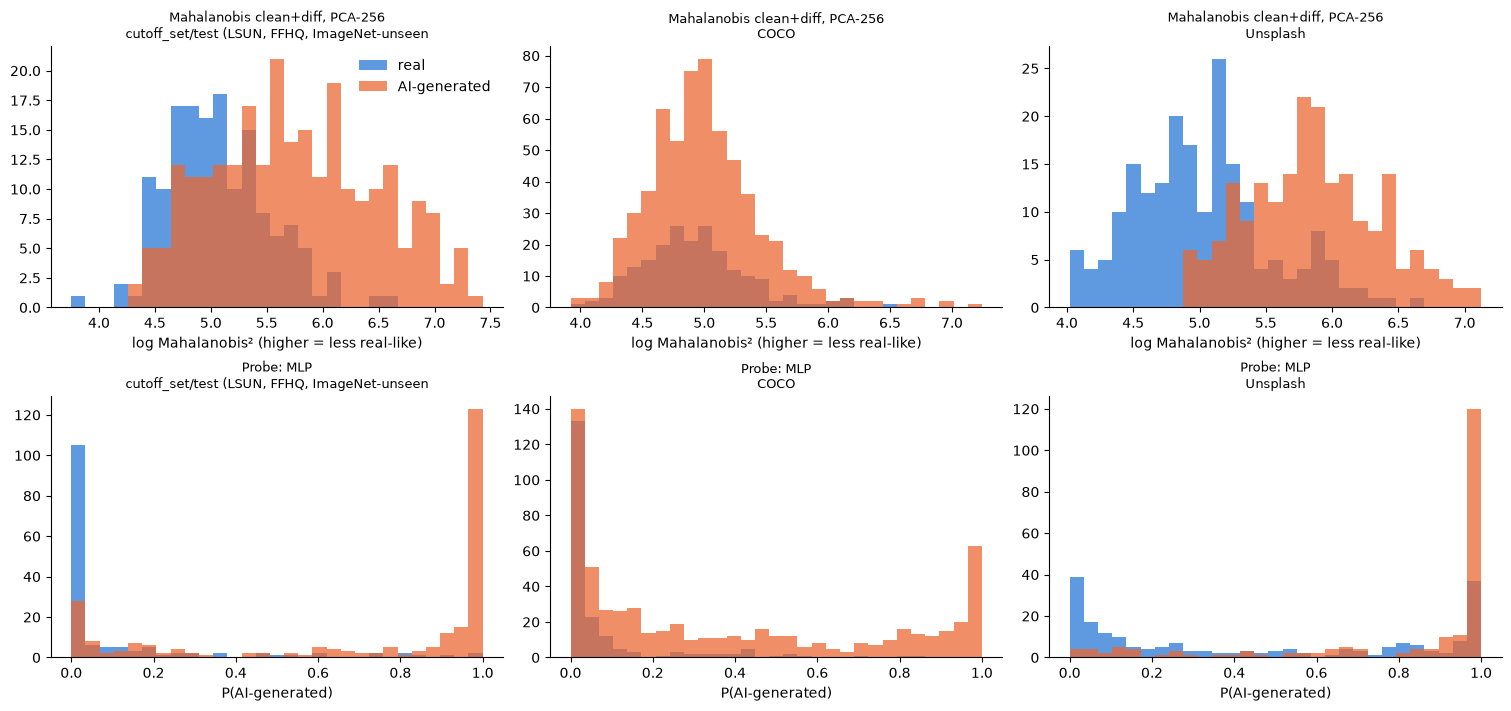

In [7]:
best = auc[overall].xs("real only", level="trained on").mean(axis=1).idxmax()
print("Best anomaly detector (mean AUROC over test sets):", best)
REAL_C, FAKE_C = "#2a78d6", "#eb6834"
fig, axes = plt.subplots(2, len(evals), figsize=(5 * len(evals), 7), layout="constrained")
for row_ax, det in zip(axes, [best, "Probe: MLP"]):
    score = detectors[det][1]
    for ax, (name, e) in zip(row_ax, evals.items()):
        s = score(e["clean"], e["noisy"])
        if det.startswith("Mahalanobis"):
            s = np.log(s)                     # squared distances are heavy-tailed
        bins = np.linspace(s.min(), s.max(), 30)
        ax.hist(s[e["label"] == 1], bins=bins, color=REAL_C, alpha=0.75, label="real")
        ax.hist(s[e["label"] == 0], bins=bins, color=FAKE_C, alpha=0.75, label="AI-generated")
        ax.set_title(f"{det}\n{name.split(' |')[0]}", fontsize=9)
        ax.set_xlabel("log Mahalanobis² (higher = less real-like)" if det.startswith("Mahalanobis") else "P(AI-generated)")
        ax.spines[["top", "right"]].set_visible(False)
axes[0][0].legend(frameon=False)
plt.show()